# 수도권 도시지역(built-up area) 추출 — Google Earth Engine + Random Forest

Landsat 8 (2020) 위성영상 → 토지피복 감독분류(5개 클래스) → 시가화지역 추출

| 단계 | 내용 |
|---|---|
| 1. Data preparation | Landsat 8 영상 호출, 구름 제거, 연간 중앙값 합성, 수도권 행정경계로 Clip |
| 2. Training samples | 5개 클래스(도시·수역·산림·농경지·초지/나지) 훈련 샘플 생성 |
| 3. Supervised classification | Random Forest 분류 및 정확도 평가 |
| 4. Extracting built-up area | 도시 클래스 추출, 시도별 면적 산출, GeoTIFF 내보내기 |

**사전 준비**
- Google Earth Engine 계정 및 Cloud 프로젝트 등록 (https://code.earthengine.google.com/register)
- 아래 `PROJECT`에 본인 Cloud 프로젝트 ID 입력

## 0. 환경 설정 및 인증

In [7]:
# geemap: Earth Engine 결과를 Colab 지도 위에 띄워 주는 라이브러리
# earthengine-api: 파이썬에서 Google Earth Engine(GEE)을 쓰기 위한 공식 패키지
# koreanize-matplotlib: 그래프 한글 깨짐 방지   (-q: 설치 로그 생략)
!pip -q install geemap earthengine-api koreanize-matplotlib

In [8]:
import ee                         # Earth Engine 파이썬 API
import geemap                     # 대화형 지도 시각화
import requests                   # 썸네일 이미지 내려받기(HTTP 요청)
from io import BytesIO           # 내려받은 바이트를 파일처럼 다루기
from PIL import Image            # 이미지 열기
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches   # 범례용 색 상자
import koreanize_matplotlib

PROJECT = "gen-lang-client-0542009343"   # ← Earth Engine 비상업용으로 등록된 Cloud 프로젝트 ID

# GEE는 구글 서버에서 계산하므로 (1) 내 계정 인증 → (2) 어떤 Cloud 프로젝트로 쓸지 지정 이 필요
ee.Authenticate()                 # 처음 한 번 구글 계정 로그인 창이 뜸 (이후엔 저장된 인증 사용)
ee.Initialize(project=PROJECT)    # 이 프로젝트의 사용량(무료 할당량)으로 계산 요청

---
## 1. Data preparation

### 1-1. 수도권 행정경계
- 통계지리정보서비스(SGIS) **2025년 2분기 시도 경계 SHP**(`bnd_sido_00_2025_2Q.shp`)에서 서울·인천·경기 선택
- Google Drive에 있는 SHP를 `geopandas`로 읽고 → 30m 허용오차로 단순화 → EPSG:4326 변환 → `geemap.gdf_to_ee`로 Earth Engine FeatureCollection으로 변환
- 이후 셀과의 호환을 위해 시도명을 `ADM1_NAME` 속성에도 넣어 둠

In [40]:
# Google Drive를 /content/drive 경로에 연결 → Drive에 있는 SHP 읽기, 결과 저장에 필요
from google.colab import drive
drive.mount('/content/drive')

import os, glob

# ===== 작업 폴더(노트북이 있는 폴더) 설정 =====
# Colab은 항상 /content에서 시작하므로, 노트북이 있는 폴더로 이동(chdir)해 두면
# 이후에는 "image/...", "output/..." 같은 상대경로로 파일을 찾을 수 있음
BASE_DIR = "/content/drive/MyDrive/Colab Notebooks/5_스마트도시데이터분석_colab/lecture10_advanced_models"
if not os.path.isdir(BASE_DIR):
    # 폴더를 옮겼거나 이름이 바뀐 경우: Drive에서 이 노트북 파일을 찾아 그 폴더를 사용
    hits = glob.glob("/content/drive/MyDrive/**/실습5_수도권_시가화지역_추출_GEE.ipynb", recursive=True)
    if not hits:
        raise FileNotFoundError("노트북 폴더를 찾지 못했습니다. BASE_DIR을 직접 수정하세요.")
    BASE_DIR = os.path.dirname(hits[0])
os.chdir(BASE_DIR)
print("작업 폴더:", os.getcwd())

# ===== 상대경로 =====
SHP_DIR   = "bnd_all_00_2025_2Q"     # SGIS 행정경계 SHP
IMAGE_DIR = "image"                  # 그림(PNG) 저장
OUT_DIR   = "output"                 # GeoTIFF 저장
for d in (IMAGE_DIR, OUT_DIR):
    os.makedirs(d, exist_ok=True)    # 없으면 새로 만듦
print("폴더 확인:", {d: os.path.isdir(d) for d in (SHP_DIR, IMAGE_DIR, OUT_DIR)})

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
작업 폴더: /content/drive/MyDrive/Colab Notebooks/5_스마트도시데이터분석_colab/lecture10_advanced_models
폴더 확인: {'bnd_all_00_2025_2Q': True, 'image': True, 'output': True}


In [34]:
import geopandas as gpd

# ===== 1) SGIS 시도 경계 SHP 읽기 =====
SHP = os.path.join(SHP_DIR, "bnd_sido_00_2025_2Q.shp")   # 작업 폴더 기준 상대경로

sido = gpd.read_file(SHP)
# SGIS 파일은 인코딩(cp949/utf-8)이 버전마다 달라 한글이 깨질 수 있음 → 깨지면 cp949로 다시 읽기
if not sido["SIDO_NM"].astype(str).str.contains("서울").any():
    sido = gpd.read_file(SHP, encoding="cp949")
print("좌표계:", sido.crs)
print("전체 시도:", sido["SIDO_NM"].tolist())

# ===== 2) 서울·인천·경기만 선택 =====
cap_gdf = sido[sido["SIDO_NM"].str.contains("서울|인천|경기")].copy()

# ===== 3) GEE 업로드용 정리 =====
# - 원본 경계는 매우 정밀해서(꼭짓점 수가 많음) 그대로 올리면 요청 용량 초과 위험
#   → Landsat 해상도(30m)에 맞춰 30m 허용오차로 단순화 (원본 좌표계가 미터 단위라 가능)
# - GEE는 경위도(EPSG:4326)를 사용하므로 좌표계 변환
cap_gdf["geometry"] = cap_gdf.geometry.simplify(30, preserve_topology=True)
cap_gdf = cap_gdf.to_crs(epsg=4326)
# 아래 셀(시도별 면적 산출 등)이 ADM1_NAME 속성을 쓰므로 같은 이름으로 시도명 복사
cap_gdf["ADM1_NAME"] = cap_gdf["SIDO_NM"]
cap_gdf = cap_gdf[["SIDO_CD", "SIDO_NM", "ADM1_NAME", "geometry"]]

# ===== 4) GeoDataFrame → Earth Engine FeatureCollection =====
capital = geemap.gdf_to_ee(cap_gdf)

roi = capital.geometry()
print("선택된 시도:", capital.aggregate_array("ADM1_NAME").getInfo())
print(f"면적: {roi.area(maxError=100).divide(1e6).getInfo():,.0f} km²")

좌표계: EPSG:5179
전체 시도: ['서울특별시', '부산광역시', '대구광역시', '인천광역시', '광주광역시', '대전광역시', '울산광역시', '세종특별자치시', '경기도', '강원특별자치도', '충청북도', '충청남도', '전북특별자치도', '전라남도', '경상북도', '경상남도', '제주특별자치도']
선택된 시도: ['서울특별시', '인천광역시', '경기도']
면적: 12,057 km²


### 1-2. Landsat 8 영상 호출 및 전처리
- 데이터: Landsat 8 Collection 2, Level 2 (지표면 반사율, Surface Reflectance)
- 구름·구름 그림자·눈 픽셀 제거 (`QA_PIXEL` 비트 마스크)
- 반사율 환산: `DN × 0.0000275 − 0.2`
- 2020년 전체 영상의 **중앙값 합성(median composite)** → 구름 없는 단일 영상 생성
- 분광지수 추가: NDVI(식생), MNDWI(수역), NDBI(시가지)

In [11]:
YEAR = 2020     # 분석 연도 (훈련 라벨인 ESA WorldCover v100이 2020년 지도라 연도를 맞춤)

# ===== 구름 제거 + 반사율 변환 함수 (영상 한 장마다 적용) =====
def mask_and_scale(img):
    # QA_PIXEL: 픽셀마다 구름·그림자 등의 여부를 비트(0/1)로 기록한 품질 밴드
    qa = img.select("QA_PIXEL")
    # bitwiseAnd(1 << n): n번째 비트만 꺼내기 → 0이면 해당 현상 없음
    clear = (qa.bitwiseAnd(1 << 1).eq(0)        # dilated cloud (구름 주변 확장 영역)
             .And(qa.bitwiseAnd(1 << 3).eq(0))  # cloud (구름)
             .And(qa.bitwiseAnd(1 << 4).eq(0))  # cloud shadow (구름 그림자)
             .And(qa.bitwiseAnd(1 << 5).eq(0))) # snow (눈)
    # SR_B2~B7: 청·녹·적·근적외·단파적외1·단파적외2 밴드
    # 저장값(DN)을 실제 지표면 반사율(0~1)로 환산: DN × 0.0000275 − 0.2 (USGS 공식 계수)
    sr = img.select("SR_B[2-7]").multiply(0.0000275).add(-0.2)
    # 맑은 픽셀만 남기고(나머지는 투명 처리), 촬영 날짜 속성은 그대로 복사
    return sr.updateMask(clear).copyProperties(img, ["system:time_start"])

# ===== Landsat 8 영상 모음 불러오기 =====
collection = (ee.ImageCollection("LANDSAT/LC08/C02/T1_L2")   # Landsat 8, Collection 2, Level 2(지표면 반사율)
              .filterBounds(roi)                               # 수도권과 겹치는 영상만
              .filterDate(f"{YEAR}-01-01", f"{YEAR+1}-01-01")  # 해당 연도 1년치
              .filter(ee.Filter.lt("CLOUD_COVER", 50))         # 구름 50% 미만 장면만
              .map(mask_and_scale))                            # 모든 영상에 위 함수 적용
print("사용 영상 수:", collection.size().getInfo())            # getInfo(): 서버 계산 결과를 Colab으로 가져오기

# ===== 중앙값 합성 =====
# 같은 위치의 1년치 픽셀 값 중 중앙값 선택 → 구름이 남은 값(너무 밝음)·그림자(너무 어두움)가 자연스럽게 걸러짐
composite = (collection.median()
             .rename(["blue", "green", "red", "nir", "swir1", "swir2"])   # 밴드 이름을 알아보기 쉽게
             .clip(roi))                                                   # 수도권 경계 밖은 잘라냄

# ===== 분광지수: (A − B) / (A + B) 형태의 정규화 차이 =====
ndvi  = composite.normalizedDifference(["nir", "red"]).rename("NDVI")      # 식생: 식물은 근적외선 강하게 반사 → 값 큼
mndwi = composite.normalizedDifference(["green", "swir1"]).rename("MNDWI") # 수역: 물은 단파적외선 흡수 → 값 큼
ndbi  = composite.normalizedDifference(["swir1", "nir"]).rename("NDBI")    # 시가지: 콘크리트·지붕은 단파적외선 반사 큼 → 값 큼
image = composite.addBands([ndvi, mndwi, ndbi])                            # 반사율 6개 + 지수 3개 = 9개 밴드

BANDS = image.bandNames().getInfo()
print("분류 입력 밴드:", BANDS)

사용 영상 수: 103
분류 입력 밴드: ['blue', 'green', 'red', 'nir', 'swir1', 'swir2', 'NDVI', 'MNDWI', 'NDBI']


### 1-3. 영상 확인
- **True color** (R-G-B): 육안 판독용
- **False color** (NIR-R-G): 식생이 붉게 표시 → 식생·시가지·수역 구분이 쉬움 (슬라이드 2번째 그림)

In [18]:
# ===== 시각화 설정 =====
# 반사율 0~0.25 범위를 화면 밝기 0~255로 늘려 표시, gamma로 어두운 부분을 조금 밝게
VIS_TRUE  = {"bands": ["red", "green", "blue"], "min": 0.0, "max": 0.25, "gamma": 1.2}   # 사람 눈과 같은 천연색
VIS_FALSE = {"bands": ["nir", "red", "green"], "min": 0.0, "max": 0.40}                # 위색: 식생이 빨갛게 보임

# 배경지도: geemap 기본값인 OpenStreetMap은 Colab에서 차단(403 Access blocked)되므로 Esri 회색 배경 사용
#          위성 배경을 원하면 basemap="Esri.WorldImagery"
Map = geemap.Map(center=[37.45, 127.0], zoom=9, basemap="Esri.WorldGrayCanvas")   # 수도권 중심, 확대 수준 9
Map.addLayer(image, VIS_TRUE, "True color")                                       # 레이어 추가 (이름은 오른쪽 위 레이어 목록에 표시)
Map.addLayer(image, VIS_FALSE, "False color (NIR-R-G)", False)                    # 마지막 False: 처음엔 꺼 둔 상태
# ee.Image().byte().paint(경계, 값, 선 두께): 빈 이미지 위에 경계선만 그리기 (면은 투명)
Map.addLayer(ee.Image().byte().paint(capital, 1, 2), {"palette": ["000000"]}, "수도권 경계")
Map

Map(center=[37.45, 127.0], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright'…

---
## 2. Training samples

**클래스 정의**

| 코드 | 클래스 | 색상 |
|---|---|---|
| 0 | 도시 (built-up) | 빨강 |
| 1 | 수역 (water) | 파랑 |
| 2 | 산림 (forest) | 초록 |
| 3 | 농경지 (cropland) | 노랑 |
| 4 | 초지·나지 (grass/bare) | 황갈 |

**샘플 생성 방식**
- 슬라이드의 원래 방식은 밴드 조합을 바꿔가며 **화면에서 직접 샘플을 찍는 방식**
- 이 노트북은 재현성을 위해 **ESA WorldCover 2020(10m) 토지피복도**에서 클래스별 샘플을 자동 추출
  - 경계부 오분류를 줄이기 위해 주변 3×3 픽셀이 모두 같은 클래스인 **균질 지점**만 사용
  - 갯벌 등 습지(wetland)는 분광 특성이 모호해 샘플에서 제외
- 직접 찍은 샘플을 쓰려면: Code Editor에서 클래스별 포인트를 그려 `landcover` 속성(0~4)을 부여 → Asset으로 저장 → 아래 대안 코드 사용

In [19]:
CLASS_NAMES = ["도시", "수역", "산림", "농경지", "초지·나지"]          # 클래스 코드 0~4의 이름
PALETTE     = ["ff0000", "0000ff", "008000", "ffff00", "c8b464"]   # 지도 표시 색상 (빨강·파랑·초록·노랑·황갈)

# ===== 정답 라벨 만들기: ESA WorldCover 2020 (10m 토지피복도) =====
# WorldCover 코드 → 5개 클래스
# 50 built-up → 0 | 80 water → 1 | 10 tree, 20 shrub → 2 | 40 cropland → 3 | 30 grass, 60 bare → 4
wc = ee.ImageCollection("ESA/WorldCover/v100").first().select("Map")
# remap(원래 값 목록, 바꿀 값 목록): 11개 WorldCover 코드를 5개 클래스로 묶기 (목록에 없는 습지 등은 제외됨)
label = wc.remap([50, 80, 10, 20, 40, 30, 60], [0, 1, 2, 2, 3, 4, 4]).rename("landcover").toInt()

# ===== 균질 픽셀만 남기기 =====
# 주변 3×3 픽셀의 최솟값 = 최댓값이면 9칸이 모두 같은 클래스 → 경계부(섞인 픽셀)의 애매한 샘플 제거
mm = label.reduceNeighborhood(ee.Reducer.minMax(), ee.Kernel.square(1))   # square(1): 반경 1픽셀 = 3×3
label = label.updateMask(mm.select("landcover_min").eq(mm.select("landcover_max")))

# ===== 층화 표본 추출: 클래스마다 최대 600개씩 무작위 지점 뽑기 =====
# - 영상(9개 밴드) + 라벨을 합친 뒤, 각 지점의 밴드 값과 정답을 함께 추출
# - 층화(stratified): 면적이 작은 클래스(수역 등)도 충분히 뽑히도록 클래스별로 따로 추출
samples = image.addBands(label).stratifiedSample(
    numPoints=600, classBand="landcover", region=roi,
    scale=30,              # Landsat 해상도(30m) 기준으로 추출
    seed=42,               # 같은 지점이 뽑히도록 고정 (재현성)
    geometries=True,       # 지도에 찍어 볼 수 있게 좌표 포함
    tileScale=4)           # 계산을 잘게 나눠 메모리 초과 오류 방지

# 대안: 직접 찍은 샘플 Asset 사용 시
# samples = image.sampleRegions(
#     collection=ee.FeatureCollection("projects/your-project/assets/training_points"),
#     properties=["landcover"], scale=30, geometries=True)

# ===== 학습 70% / 검증 30% 나누기 =====
samples = samples.randomColumn("rand", seed=42)       # 각 샘플에 0~1 난수 부여
train = samples.filter(ee.Filter.lt("rand", 0.7))     # 0.7 미만 → 학습용
test  = samples.filter(ee.Filter.gte("rand", 0.7))    # 0.7 이상 → 검증용 (모델이 보지 못한 데이터)

# 클래스별 샘플 개수 확인
hist = samples.aggregate_histogram("landcover").getInfo()      # {"0": 개수, "1": 개수, ...}
for k, v in sorted(hist.items(), key=lambda t: int(t[0])):
    print(f"{CLASS_NAMES[int(k)]:<6}: {v}개")
print("train:", train.size().getInfo(), " test:", test.size().getInfo())

도시    : 600개
수역    : 600개
산림    : 600개
농경지   : 600개
초지·나지 : 600개
train: 2111  test: 889


In [20]:
# 클래스별 색상으로 샘플 지점 표시
def style_point(f):
    # 지점의 landcover 값(0~4)을 인덱스로 PALETTE에서 색상을 꺼냄
    color = ee.List(PALETTE).get(f.getNumber("landcover").toInt())
    return f.set("style", {"color": color, "pointSize": 3, "width": 0})   # 점 크기 3, 테두리 없음

# 지점마다 저장한 style 속성대로 그린 이미지 만들기
train_vis = train.map(style_point).style(styleProperty="style")

# 배경지도: geemap 기본값인 OpenStreetMap은 Colab에서 차단(403 Access blocked)되므로 Esri 회색 배경 사용
#          위성 배경을 원하면 basemap="Esri.WorldImagery"
Map = geemap.Map(center=[37.45, 127.0], zoom=9, basemap="Esri.WorldGrayCanvas")
Map.addLayer(image, VIS_FALSE, "False color")          # 위색 영상 위에
Map.addLayer(train_vis, {}, "Training samples")        # 학습 샘플 점을 겹쳐 표시
Map.add_legend(title="토지피복", legend_dict=dict(zip(CLASS_NAMES, PALETTE)))   # 클래스 이름-색상 범례
Map

Map(center=[37.45, 127.0], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright'…

---
## 3. Supervised classification

### 3-1. Random Forest 학습 및 분류
- 트리 100개, 입력: 반사율 6개 밴드 + 분광지수 3개

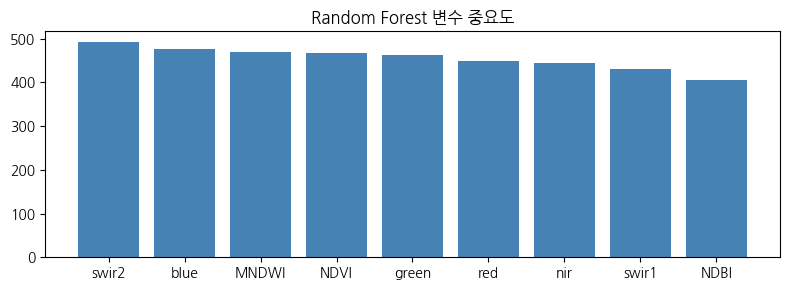

In [21]:
# ===== Random Forest 학습 =====
# 결정트리 100개를 서로 다른 샘플·변수 조합으로 만들고, 다수결로 클래스를 정하는 분류기
rf = ee.Classifier.smileRandomForest(numberOfTrees=100, seed=42).train(
    features=train,              # 학습 샘플 (각 지점의 9개 밴드 값 + 정답)
    classProperty="landcover",   # 정답이 들어 있는 속성 이름
    inputProperties=BANDS)       # 입력 변수: 반사율 6개 + 분광지수 3개

# 학습된 모델을 수도권 전체 픽셀에 적용 → 픽셀마다 0~4 클래스 값을 가진 분류 지도
classified = image.select(BANDS).classify(rf).rename("landcover")

# ===== 변수 중요도 =====
# 각 밴드가 분류에 얼마나 기여했는지 (값이 클수록 클래스 구분에 중요)
importance = rf.explain().get("importance").getInfo()
imp = dict(sorted(importance.items(), key=lambda t: t[1], reverse=True))   # 중요도 큰 순으로 정렬
plt.figure(figsize=(8, 3))
plt.bar(imp.keys(), imp.values(), color="steelblue")
plt.title("Random Forest 변수 중요도"); plt.tight_layout(); plt.show()

### 3-2. 정확도 평가 (검증 샘플 30%)
- 전체 정확도(overall accuracy), Kappa 계수
- 생산자 정확도(producer's accuracy, 누락 오류 관련) / 사용자 정확도(user's accuracy, 포함 오류 관련)

In [22]:
# 검증 샘플(학습에 안 쓴 30%)을 모델로 분류 → 각 지점에 "classification"(예측) 속성 추가
validated = test.classify(rf)
# 오차행렬: 정답(landcover)과 예측(classification)을 교차 집계한 표
cm = validated.errorMatrix("landcover", "classification")

print("오차행렬 (행: 정답, 열: 예측)")        # 대각선 = 맞힌 개수, 나머지 = 다른 클래스로 잘못 분류된 개수
for name, row in zip(CLASS_NAMES, cm.getInfo()):
    print(f"  {name:<6}", row)
print(f"\n전체 정확도: {cm.accuracy().getInfo():.3f}")   # 맞힌 샘플 수 / 전체 샘플 수
print(f"Kappa:       {cm.kappa().getInfo():.3f}")         # 우연히 맞힐 확률을 뺀 일치도 (0.8 이상이면 매우 좋음)

# 생산자 정확도: 실제 그 클래스인 것 중 맞게 찾은 비율 (낮으면 "놓친 것"이 많음 = 누락 오류)
# 사용자 정확도: 그 클래스라고 예측한 것 중 실제로 맞은 비율 (낮으면 "잘못 포함"이 많음 = 포함 오류)
pa = [r[0] for r in cm.producersAccuracy().getInfo()]   # [[a],[b],...] 모양이라 꺼내서 1차원으로
ua = cm.consumersAccuracy().getInfo()[0]                 # [[a, b, ...]] 모양이라 첫 행만
for n, p, u in zip(CLASS_NAMES, pa, ua):
    print(f"  {n:<6} 생산자 정확도={p:.3f}  사용자 정확도={u:.3f}")

오차행렬 (행: 정답, 열: 예측)
  도시     [136, 2, 1, 9, 13]
  수역     [3, 175, 0, 0, 0]
  산림     [1, 0, 201, 1, 3]
  농경지    [17, 2, 2, 128, 23]
  초지·나지  [26, 2, 10, 21, 113]

전체 정확도: 0.847
Kappa:       0.808
  도시     생산자 정확도=0.845  사용자 정확도=0.743
  수역     생산자 정확도=0.983  사용자 정확도=0.967
  산림     생산자 정확도=0.976  사용자 정확도=0.939
  농경지    생산자 정확도=0.744  사용자 정확도=0.805
  초지·나지  생산자 정확도=0.657  사용자 정확도=0.743


In [23]:
# 배경지도: geemap 기본값인 OpenStreetMap은 Colab에서 차단(403 Access blocked)되므로 Esri 회색 배경 사용
#          위성 배경을 원하면 basemap="Esri.WorldImagery"
Map = geemap.Map(center=[37.45, 127.0], zoom=9, basemap="Esri.WorldGrayCanvas")
Map.addLayer(image, VIS_TRUE, "True color", False)     # 비교용 천연색 영상 (처음엔 꺼 둠)
# 분류 결과: 값 0~4를 PALETTE 색상에 순서대로 대응
Map.addLayer(classified, {"min": 0, "max": 4, "palette": PALETTE}, "토지피복분류")
Map.add_legend(title="토지피복", legend_dict=dict(zip(CLASS_NAMES, PALETTE)))
Map

Map(center=[37.45, 127.0], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright'…

---
## 4. Extracting built-up area

### 4-1. 도시 클래스 추출 및 면적 산출
- 분류 결과에서 도시(0) 클래스만 추출
- 수도권 전체 및 시도별 시가화 면적·비율 계산

In [24]:
# ===== 도시 클래스만 추출 =====
# eq(0): 도시면 1, 아니면 0 → selfMask(): 0인 픽셀을 투명 처리 → 도시 픽셀만 남음
built = classified.eq(0).selfMask().rename("built")

# ===== 면적 계산 =====
# pixelArea(): 각 픽셀의 실제 면적(m²) → 1e6으로 나눠 km²
area_img = ee.Image.pixelArea().divide(1e6)             # km²
stats = (area_img.updateMask(built).rename("built_km2")   # 밴드 1: 도시 픽셀의 면적만
         .addBands(area_img.rename("total_km2"))          # 밴드 2: 모든 픽셀의 면적
         # 시도 경계(capital)마다 두 밴드의 합계 계산 → 시도별 시가화 면적·전체 면적
         .reduceRegions(collection=capital, reducer=ee.Reducer.sum(), scale=30, tileScale=4))

# 결과를 Colab으로 가져와 표로 출력
rows = stats.select(["ADM1_NAME", "built_km2", "total_km2"]).getInfo()["features"]
tot_b = tot_a = 0                                        # 수도권 합계 (시가화 면적, 전체 면적)
print(f"{'시도':<20}{'시가화 면적(km²)':>16}{'비율':>8}")
for f in rows:
    p = f["properties"]
    tot_b += p["built_km2"]; tot_a += p["total_km2"]
    # :>16,.1f → 오른쪽 정렬 16칸·천 단위 콤마·소수 1자리,  :>8.1% → 백분율 소수 1자리
    print(f"{p['ADM1_NAME']:<20}{p['built_km2']:>16,.1f}{p['built_km2']/p['total_km2']:>8.1%}")
print(f"{'수도권 전체':<18}{tot_b:>16,.1f}{tot_b/tot_a:>8.1%}")

시도                       시가화 면적(km²)      비율
서울특별시                          323.4   53.4%
인천광역시                          293.9   26.5%
경기도                          1,242.2   12.0%
수도권 전체                     1,859.5   15.4%


In [25]:
# 배경지도: geemap 기본값인 OpenStreetMap은 Colab에서 차단(403 Access blocked)되므로 Esri 회색 배경 사용
#          위성 배경을 원하면 basemap="Esri.WorldImagery"
Map = geemap.Map(center=[37.45, 127.0], zoom=9, basemap="Esri.WorldGrayCanvas")
Map.addLayer(built, {"palette": ["ff0000"]}, "Built-up area")       # 시가화지역을 빨간색으로
Map.addLayer(ee.Image().byte().paint(capital, 1, 1), {"palette": ["000000"]}, "수도권 경계")   # 시도 경계선(두께 1)
Map

Map(center=[37.45, 127.0], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright'…

### 4-2. 슬라이드용 4단계 그림 생성
- 각 단계 결과를 이미지로 받아 한 장의 그림으로 정리 (발표자료 삽입용 PNG 저장)

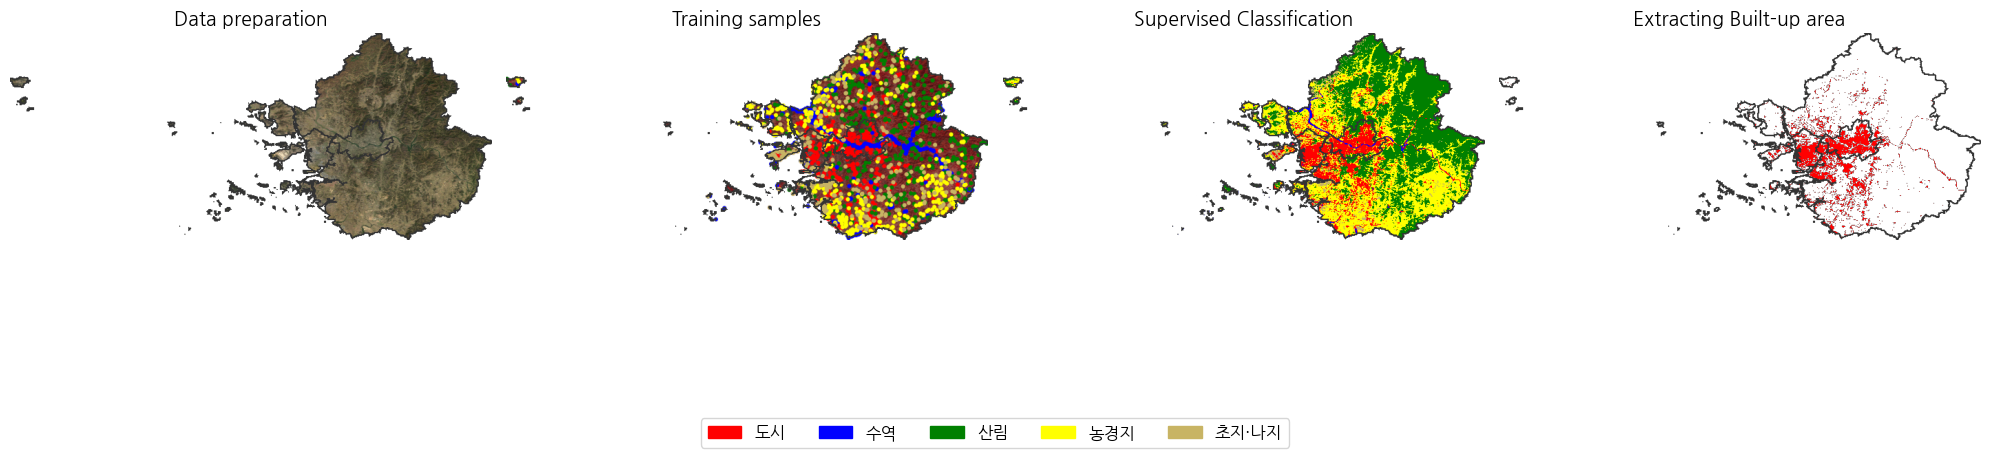

In [35]:
# ===== 슬라이드용 4단계 그림 =====
region = roi.bounds()      # 수도권을 감싸는 직사각형 (썸네일 범위)
# 시도 경계선을 진회색으로 그린 이미지 → 모든 패널 위에 겹쳐 표시
outline = ee.Image().byte().paint(capital, 1, 2).visualize(palette=["333333"])

# GEE 이미지를 PNG 썸네일로 받아 PIL 이미지로 변환하는 함수
def thumb(vis_img, dim=700):
    # blend: 위에 경계선 겹치기 / getThumbURL: GEE 서버가 PNG를 만들어 주는 주소 / dim: 긴 변 픽셀 수
    url = vis_img.blend(outline).getThumbURL({"region": region, "dimensions": dim, "format": "png"})
    return Image.open(BytesIO(requests.get(url).content))

# (제목, 시각화된 이미지) 4쌍. visualize(): 색상 설정을 적용해 RGB 이미지로 확정
panels = [
    ("Data preparation",          image.visualize(**VIS_TRUE)),                     # 1. 천연색 합성 영상
    ("Training samples",          image.visualize(**VIS_FALSE).blend(train_vis)),   # 2. 위색 영상 + 학습 샘플
    ("Supervised Classification", classified.visualize(min=0, max=4, palette=PALETTE)),   # 3. 분류 결과
    ("Extracting Built-up area",  built.visualize(palette=["ff0000"])),             # 4. 시가화지역
]

fig, axes = plt.subplots(1, 4, figsize=(20, 6))      # 1행 4열
for ax, (title, vis) in zip(axes, panels):
    ax.imshow(thumb(vis)); ax.set_title(title, fontsize=14); ax.axis("off")
# 그림 아래쪽에 클래스 범례 (5개를 한 줄로)
handles = [mpatches.Patch(color="#" + c, label=n) for n, c in zip(CLASS_NAMES, PALETTE)]
fig.legend(handles=handles, loc="lower center", ncol=5, fontsize=12)
plt.tight_layout(rect=[0, 0.06, 1, 1])              # 아래 6%는 범례 자리로 비워 둠
plt.savefig(os.path.join(IMAGE_DIR, "builtup_workflow.png"), dpi=200, bbox_inches="tight")   # 발표자료용 고해상도 PNG → image 폴더에 저장
plt.show()

### 4-3. GeoTIFF 내보내기 (Google Drive 지정 폴더)
- 저장 위치: 작업 폴더(`lecture10_advanced_models`) 안의 `output` 폴더 (상대경로)
- 좌표계: EPSG:5186 (Korea 2000 / Central Belt 2010), 해상도 30m
- `ee.batch.Export.image.toDrive`는 `folder`에 **폴더 이름 하나만** 받아(하위 경로 지정 불가) 원하는 위치에 저장할 수 없음
  → `geemap.download_ee_image`로 마운트된 Drive 경로에 직접 저장 (큰 영상은 자동으로 타일로 나눠 받은 뒤 합침)

In [36]:
# geedim: geemap.download_ee_image가 내부적으로 사용하는 패키지 (큰 영상을 타일로 나눠 내려받기)
!pip -q install geedim
import os

# ===== 저장 폴더: 작업 폴더 기준 상대경로 output (0. 환경 설정에서 정의) =====
os.makedirs(OUT_DIR, exist_ok=True)          # 폴더가 없으면 새로 만듦

exports = {
    f"capital_landcover_{YEAR}": classified.toByte(),            # 5개 클래스 분류 지도 (toByte: 0~255 정수로 용량 절약)
    f"capital_builtup_{YEAR}":   classified.eq(0).toByte(),      # 1 = 도시, 0 = 비도시
}

# ===== 지정 경로로 GeoTIFF 직접 저장 =====
# Export.image.toDrive는 folder에 "폴더 이름"만 받아 하위 경로(.../lecture10_advanced_models/output) 지정이 불가능
# → Colab에 마운트된 Drive 경로에 바로 내려받는 geemap.download_ee_image 사용
for name, img in exports.items():
    path = os.path.join(OUT_DIR, f"{name}.tif")
    print("저장 중:", path)
    geemap.download_ee_image(
        img.clip(roi),           # 수도권 경계 밖 제거 (경계 밖은 NoData)
        filename=path,
        region=region,           # 내보낼 범위 (수도권을 감싸는 직사각형, 4-2에서 정의)
        scale=30,                # 해상도 30m
        crs="EPSG:5186",         # 좌표계: Korea 2000 / Central Belt 2010 (국내 GIS 표준, 미터 단위)
        dtype="uint8",           # 0~255 정수형으로 저장
        overwrite=True)          # 같은 이름 파일이 있으면 덮어쓰기

저장 중: output/capital_landcover_2020.tif


  0%|          |0/33 tiles [00:00<?]

저장 중: output/capital_builtup_2020.tif


  0%|          |0/33 tiles [00:00<?]

In [37]:
# ===== 저장 결과 확인: 파일 크기와 래스터 정보 =====
import rasterio
for name in exports:
    path = os.path.join(OUT_DIR, f"{name}.tif")
    with rasterio.open(path) as src:
        print(f"{name}.tif  {os.path.getsize(path)/1e6:.1f} MB | "
              f"크기 {src.width}×{src.height} | 좌표계 {src.crs} | 해상도 {src.res[0]:.0f}m | 자료형 {src.dtypes[0]}")

capital_landcover_2020.tif  3.0 MB | 크기 9623×5228 | 좌표계 EPSG:5186 | 해상도 30m | 자료형 uint8
capital_builtup_2020.tif  1.4 MB | 크기 9623×5228 | 좌표계 EPSG:5186 | 해상도 30m | 자료형 uint8


---
## 참고 및 확장
- **계절 선택**: 연간 중앙값 대신 생육기(5~10월) 영상만 쓰면 산림·농경지 구분이 개선될 수 있음 (`filterDate` 수정)
- **샘플 품질**: WorldCover 기반 자동 샘플은 그 자체의 오류를 포함하므로, 오분류가 많은 지역은 직접 찍은 샘플로 보완 권장
- **검증의 한계**: 같은 출처의 샘플로 학습·검증하므로 정확도가 다소 낙관적으로 나올 수 있음 → 독립적인 검증 지점(예: 고해상도 영상 판독) 활용 권장
- **시계열 확장**: `YEAR`를 2015, 2025 등으로 바꿔 반복하면 시가화지역 변화 분석 가능